# 7주차 정책 비교: 기준선에서 하나씩 붙이기

`week7_step_by_step.ipynb`와 **같은 설정**(`configs/week7.json`, `configs/policies_week7.json`, W0 1배 · W1 2배 · W1 4배, seed 5개)에서 정책을 하나씩 붙여 가며 비교합니다.

- 기준선: Pin-All (대기 중에도 유지)
- 단계 1: Evict/Recompute (반대 극단: 대기 시작 즉시 삭제)
- 단계 2: Fixed TTL 3초 (둘 사이: 3초 뒤 삭제)
- 단계 3: LRU Offload (지우지 않고 CPU로 옮김) ← 7주차 매트릭스에 새로 추가

각 단계는 같은 지표 3개로 판정하고, "얻은 것 / 남은 문제 → 다음 단계"로 이어 갑니다. 실제 LLM이나 GPU는 실행하지 않으며, prefill·decode·PCIe 속도는 자리표시자이므로 절대값보다 정책 간 상대 변화를 봅니다.

## 1. 실행 환경과 모듈 불러오기

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from kvbench.engine import Simulator
from kvbench.experiment import WEEK7_CONDITIONS, WEEK7_SEEDS
from kvbench.metrics import summarize
from kvbench.policies import make_policy
from kvbench.system import load_policy_params, load_system_config
from kvbench.workload import generate, load_config

pd.set_option('display.precision', 2)
print('python:', sys.version.split()[0])

python: 3.12.7


## 2. 질문과 판정 지표 3개

**질문**: 도구 대기 중인 KV Cache를 어떻게 다뤄야 다른 요청을 지키면서 세션 자신의 비용도 작게 할 수 있나.

지표를 늘리지 않고 세 개로 고정합니다. 점유율·재계산량·전송량은 판정에 쓰지 않고 원인 설명과 동작 검증에만 씁니다.

| 지표 | 보는 것 | 정의 (warm-up 이후 요청만) | summary 키 |
|---|---|---|---|
| ① 일반 요청 P95 TTFT | 다른 사용자가 입는 피해 | 완료된 normal 요청의 도착 → 첫 토큰, P95 | `normal_p95_ttft_ms` |
| ② 도구 세션 복귀 지연 P95 | 정책이 세션에 물리는 대가 | 완료된 stress 후속 턴(turn_id > 0)의 도구 완료 → 첫 토큰, P95. 재계산 · 재적재 · 입장 대기 포함 | `stress_resume_p95_ms` |
| ③ 거절 · 중단 | 서비스 실패 | 30초 안에 블록을 못 받은 normal 비율(≤ 10%), 거절로 중단된 작업 수 | `normal_reject_rate_pct`, `rejected_jobs` |

②는 이번에 `kvbench/metrics.py`에 추가했습니다. 지우면 재계산, 옮기면 재적재, 블록이 없으면 대기 시간이 모두 같은 자리에 쌓이므로 정책마다 다른 비용을 한 숫자로 비교할 수 있습니다.

## 3. 실험 설정

7주차 매트릭스 설정을 그대로 쓰고 정책만 LRU Offload 하나를 더합니다.

In [2]:
workload = load_config('configs/week7.json')
system = load_system_config('configs/system_1080ti_llama3b.json')
POLICIES = ['pin_all', 'evict_recompute', 'fixed_ttl', 'lru_offload']
LABEL = {'pin_all': 'Pin-All', 'evict_recompute': 'Evict/Recompute',
         'fixed_ttl': 'Fixed TTL 3s', 'lru_offload': 'LRU Offload'}
params = {p: load_policy_params('configs/policies_week7.json', p) for p in POLICIES}
LOADS = [load for load, _, _ in WEEK7_CONDITIONS]

display(pd.DataFrame([
    {'항목': 'stress 세션 도착률', '값': f'{workload.stress_arrival_rate_per_s} sessions/s'},
    {'항목': '실험 길이 / warm-up', '값': f'{workload.duration_ms / 1000:.0f}s / {workload.warmup_ms / 1000:.0f}s'},
    {'항목': '도구 대기 (W0)', '값': f'{workload.tool_duration_ms[0] / 1000:.0f}~{workload.tool_duration_ms[1] / 1000:.0f}s 균등'},
    {'항목': '부하 조건', '값': ', '.join(f'{load} = {wl} {lv}배' for load, wl, lv in WEEK7_CONDITIONS)},
    {'항목': 'seed', '값': ', '.join(map(str, WEEK7_SEEDS))},
    {'항목': '정책', '값': ', '.join(f'{LABEL[p]} {params[p] or ""}'.strip() for p in POLICIES)},
    {'항목': 'KV pool', '값': f'{system.gpu_kv_pool_bytes / 2**30:.0f} GiB = {system.total_blocks} blocks'},
]).set_index('항목'))

,값
항목,
stress 세션 도착률,0.2 sessions/s
실험 길이 / warm-up,60s / 10s
도구 대기 (W0),1~5s 균등
부하 조건,"1x = W0 1배, 2x = W1 2배, 4x = W1 4배"
seed,"0, 1, 2, 3, 4"
정책,"Pin-All, Evict/Recompute, Fixed TTL 3s {'ttl_m..."
KV pool,4 GiB = 2340 blocks


## 4. 60회 실행

정책 4개 × 부하 3개 × seed 5개입니다. 같은 seed·부하의 트레이스를 한 번 만들고 정책만 바꿔 재생하므로 정책 외 요인은 통제됩니다. 결과는 `results/week7_policies/summary.csv`에도 저장합니다(Git 추적 제외).

In [3]:
sims, rows = {}, []
for load, wl, lv in WEEK7_CONDITIONS:
    for seed in WEEK7_SEEDS:
        trace = generate(workload, wl, lv, seed)
        for p in POLICIES:
            sim = Simulator(trace, system, make_policy(p, params[p])).run()
            sims[(p, load, seed)] = sim
            rows.append({'policy': p, 'load': load, 'workload': wl, 'stress_level': lv, 'seed': seed,
                         **summarize(sim, workload.warmup_ms)})
raw = pd.DataFrame(rows)
out = Path('results/week7_policies')
out.mkdir(parents=True, exist_ok=True)
raw.to_csv(out / 'summary.csv', index=False)
print(len(raw), 'runs ->', (out / 'summary.csv').as_posix())

60 runs -> results/week7_policies/summary.csv


판정 지표 3개를 seed 5개 평균으로 묶는 함수입니다. ①②는 초 단위로 바꿉니다.

In [4]:
def judge(policy):
    part = raw[raw.policy == policy].groupby('load', sort=False)
    table = pd.DataFrame({
        '① 일반 TTFT (s)': part.normal_p95_ttft_ms.mean() / 1000,
        '② 복귀 지연 (s)': part.stress_resume_p95_ms.mean() / 1000,
        '③ 거절률 (%)': part.normal_reject_rate_pct.mean(),
        '③ 중단 작업': part.rejected_jobs.mean(),
    }).loc[LOADS]
    return table

def occupancy(ax, policy, load, seed, title):
    sim = sims[(policy, load, seed)]
    t = [s[0] / 1000 for s in sim.gpu.samples]
    y = [s[1] / sim.gpu.total_blocks * 100 for s in sim.gpu.samples]
    ax.step(t, y, where='post', lw=1)
    ax.axvspan(0, workload.warmup_ms / 1000, color='0.9')
    ax.axhline(90, color='gray', ls=':')
    ax.set(ylim=(0, 105), ylabel='KV pool used (%)', title=title)

def events(policy, load, seed, name):
    return [e for e in sims[(policy, load, seed)].events if e[1] == name]

## 5. 기준선: Pin-All

도구 대기 중에도 KV Cache를 GPU에 그대로 둡니다(vLLM 기본 동작). 이후 모든 단계는 이 표와 비교합니다.

In [5]:
base = judge('pin_all')
display(base)

,① 일반 TTFT (s),② 복귀 지연 (s),③ 거절률 (%),③ 중단 작업
load,,,,
1x,0.26,0.15,0.00,0.0
2x,0.26,0.08,0.00,0.0
4x,14.23,14.05,1.99,3.2


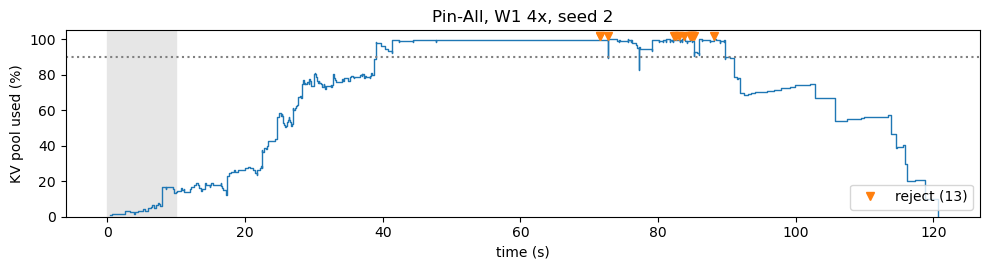

In [6]:
fig, ax = plt.subplots(figsize=(10, 2.8))
occupancy(ax, 'pin_all', '4x', 2, 'Pin-All, W1 4x, seed 2')
rejects = [e[0] / 1000 for e in events('pin_all', '4x', 2, 'REJECT')]
ax.plot(rejects, [102] * len(rejects), 'v', label=f'reject ({len(rejects)})')
ax.set_xlabel('time (s)'); ax.legend(loc='lower right')
plt.tight_layout()

**읽는 법**: 1배·2배에서는 ① 0.26초 · ② 0.15초 이하지만, 4배에서는 ① 14초 · ② 14초로 무너지고 거절과 작업 중단이 생깁니다. 도구를 기다리는 세션이 블록을 쥔 채 놓지 않아 새 요청이 30초까지 입장 대기를 하기 때문입니다(곡선이 100%에 붙은 구간).

**남은 문제 → 단계 1**: 기다리는 동안 쥐고 있는 메모리를 비우면 어떻게 되나.

## 6. 단계 1: Evict/Recompute

반대 극단입니다. 도구 대기가 시작되는 순간 지우고, 복귀하면 이전 문맥 전체를 다시 prefill합니다.

In [7]:
step1 = judge('evict_recompute')
display(pd.concat({'Evict/Recompute': step1, 'Pin-All (기준선)': base}, axis=1))

Evict/Recompute                               Pin-All (기준선)              \
       ① 일반 TTFT (s) ② 복귀 지연 (s) ③ 거절률 (%) ③ 중단 작업 ① 일반 TTFT (s) ② 복귀 지연 (s)   
load                                                                           
1x              0.63        0.99       0.0     0.0          0.26        0.15   
2x              0.49        0.81       0.0     0.0          0.26        0.08   
4x              0.47        0.86       0.0     0.0         14.23       14.05   

                        
     ③ 거절률 (%) ③ 중단 작업  
load                    
1x        0.00     0.0  
2x        0.00     0.0  
4x        1.99     3.2

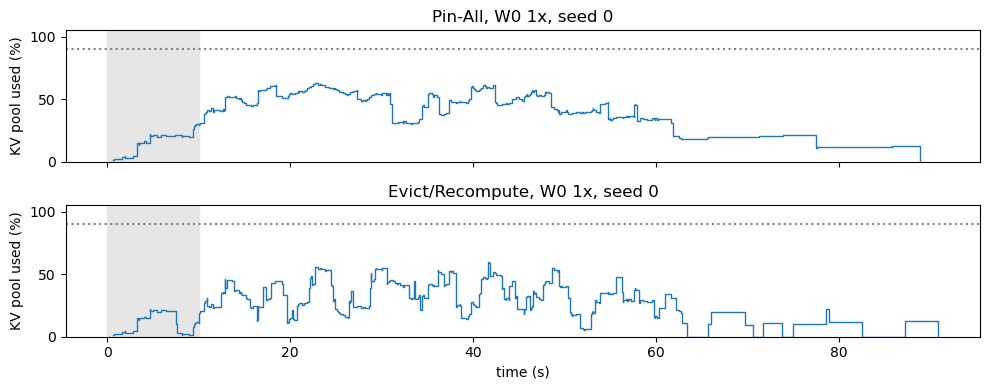

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
occupancy(axes[0], 'pin_all', '1x', 0, 'Pin-All, W0 1x, seed 0')
occupancy(axes[1], 'evict_recompute', '1x', 0, 'Evict/Recompute, W0 1x, seed 0')
axes[1].set_xlabel('time (s)')
plt.tight_layout()

**동작 검증**: 15개 run 모두 삭제 횟수가 도구 대기 횟수와 같고, 삭제 사유가 전부 idle이어야 합니다.

In [9]:
check = []
for load in LOADS:
    for seed in WEEK7_SEEDS:
        idle = len(events('evict_recompute', load, seed, 'TOOL_START'))
        evict = events('evict_recompute', load, seed, 'EVICT')
        check.append(idle == len(evict) and all('reason=idle' in e[5] for e in evict))
print('evict == tool wait in all runs:', all(check), f'({len(check)} runs)')
prefill = raw.groupby(['policy', 'load']).prefill_busy_pct.mean().unstack().loc[['pin_all', 'evict_recompute'], LOADS]
display(prefill.rename(index=LABEL).rename_axis('prefill busy (%)'))

evict == tool wait in all runs: True (15 runs)


load,1x,2x,4x
prefill busy (%),,,
Pin-All,9.48,8.43,6.63
Evict/Recompute,23.95,21.24,17.18


**얻은 것**: 모든 조건에서 거절 0, 4배에서도 ① 0.47초.

**대가**: ② 복귀 지연이 조건과 무관하게 0.8~1.0초입니다. 1초짜리 짧은 대기까지 지우고 매번 재계산하기 때문입니다. W0에서는 ①도 기준선의 2.4배인데, normal 요청 자체는 재계산하지 않지만 하나뿐인 prefill 줄에서 재계산 뒤에 서기 때문입니다(prefill 사용률 약 10% → 24%).

**남은 문제 → 단계 2**: 짧은 대기는 지키고 필요한 만큼만 지울 수 없나.

## 7. 단계 2: Fixed TTL 3초

3초 안에 돌아오는 짧은 대기는 지키고, 넘으면 지웁니다. 3초는 `week7_step_by_step.ipynb` 9절의 1·3·5초 비교에서 고른 값입니다(1초 ≈ 단계 1, 5초 ≈ 기준선).

In [10]:
step2 = judge('fixed_ttl')
display(pd.concat({'Fixed TTL 3s': step2, 'Evict/Recompute (단계 1)': step1, 'Pin-All (기준선)': base}, axis=1))

Fixed TTL 3s                               Evict/Recompute (단계 1)  \
     ① 일반 TTFT (s) ② 복귀 지연 (s) ③ 거절률 (%) ③ 중단 작업          ① 일반 TTFT (s)   
load                                                                      
1x            0.44        0.68       0.0     0.0                   0.63   
2x            0.44        0.74       0.0     0.0                   0.49   
4x            0.47        0.86       0.0     0.0                   0.47   

                                   Pin-All (기준선)                                
     ② 복귀 지연 (s) ③ 거절률 (%) ③ 중단 작업 ① 일반 TTFT (s) ② 복귀 지연 (s) ③ 거절률 (%) ③ 중단 작업  
load                                                                            
1x          0.99       0.0     0.0          0.26        0.15      0.00     0.0  
2x          0.81       0.0     0.0          0.26        0.08      0.00     0.0  
4x          0.86       0.0     0.0         14.23       14.05      1.99     3.2

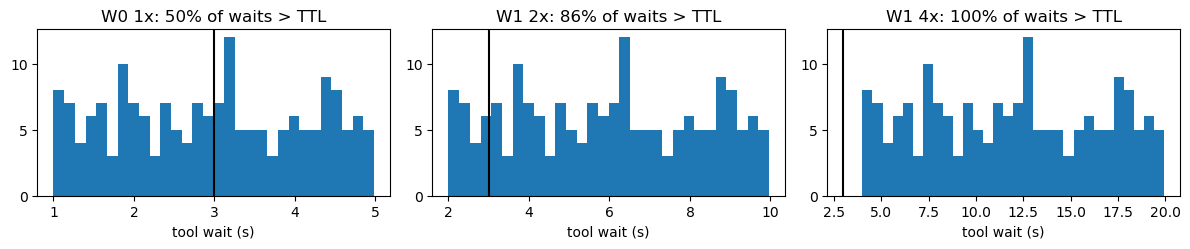

In [11]:
ttl_s = params['fixed_ttl']['ttl_ms'] / 1000
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, (load, wl, lv) in zip(axes, WEEK7_CONDITIONS):
    waits = [t.tool_duration_ms / 1000 for seed in WEEK7_SEEDS for t in generate(workload, wl, lv, seed)
             if t.request_class == 'stress' and t.tool_duration_ms > 0]
    over = sum(w > ttl_s for w in waits) / len(waits) * 100
    ax.hist(waits, bins=30)
    ax.axvline(ttl_s, color='k')
    ax.set(title=f'{wl} {lv}x: {over:.0f}% of waits > TTL', xlabel='tool wait (s)')
plt.tight_layout()

**동작 검증**: 모든 삭제가 TTL 만료로 일어나야 하고, 삭제된 대기 비율은 TTL을 넘은 대기 비율과 같아야 합니다.

In [12]:
share = {}
for load in LOADS:
    ttl_evicts = sum(len(events('fixed_ttl', load, s, 'EVICT')) for s in WEEK7_SEEDS)
    expired = sum(len(events('fixed_ttl', load, s, 'TTL_EXPIRE')) for s in WEEK7_SEEDS)
    idle = sum(len(events('fixed_ttl', load, s, 'TOOL_START')) for s in WEEK7_SEEDS)
    assert ttl_evicts == expired
    share[load] = ttl_evicts / idle * 100
print('all evictions come from TTL expiry: True')
display(pd.Series(share, name='evicted waits (%)').round(0))

all evictions come from TTL expiry: True


1x     50.0
2x     86.0
4x    100.0
Name: evicted waits (%), dtype: float64

**얻은 것**: W0에서는 대기의 절반을 지켜 ② 0.68초로 단계 1(0.99초)보다 줄고, 거절은 여전히 0입니다.

**한계**: W1 4배는 대기가 전부 3초를 넘어 숫자까지 단계 1과 같아집니다. 고정값 하나는 분포가 바뀌면 따라가지 못하고, 지우는 한 재계산 비용은 남습니다.

**남은 문제 → 단계 3**: 지우지 말고 옮기면 어떨까.

## 8. 단계 3: LRU Offload

평소에는 유지하다가 블록이 모자랄 때만, 가장 오래 기다린 세션부터 CPU 메모리로 내립니다. 복귀하면 PCIe로 다시 올립니다(재계산 없음).

In [13]:
step3 = judge('lru_offload')
display(pd.concat({'LRU Offload': step3, 'Pin-All (기준선)': base}, axis=1))

LRU Offload                               Pin-All (기준선)              \
     ① 일반 TTFT (s) ② 복귀 지연 (s) ③ 거절률 (%) ③ 중단 작업 ① 일반 TTFT (s) ② 복귀 지연 (s)   
load                                                                         
1x            0.26        0.15       0.0     0.0          0.26        0.15   
2x            0.26        0.08       0.0     0.0          0.26        0.08   
4x            0.26        0.14       0.0     0.0         14.23       14.05   

                        
     ③ 거절률 (%) ③ 중단 작업  
load                    
1x        0.00     0.0  
2x        0.00     0.0  
4x        1.99     3.2

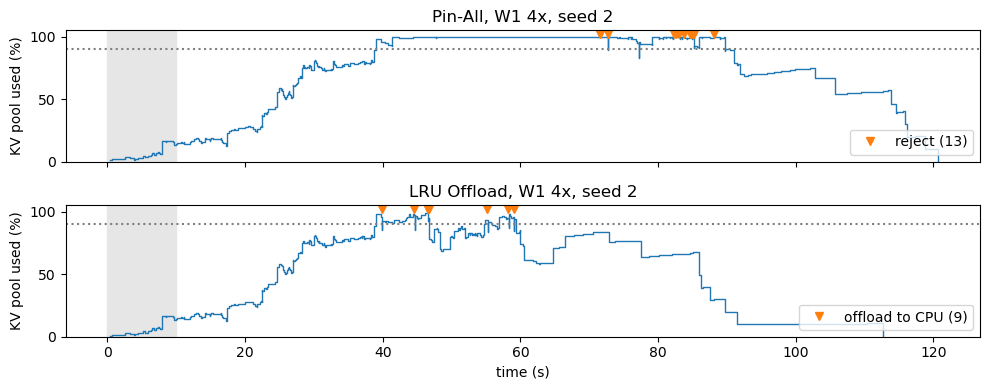

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
occupancy(axes[0], 'pin_all', '4x', 2, 'Pin-All, W1 4x, seed 2')
r = [e[0] / 1000 for e in events('pin_all', '4x', 2, 'REJECT')]
axes[0].plot(r, [102] * len(r), 'v', label=f'reject ({len(r)})'); axes[0].legend(loc='lower right')
occupancy(axes[1], 'lru_offload', '4x', 2, 'LRU Offload, W1 4x, seed 2')
o = [e[0] / 1000 for e in events('lru_offload', '4x', 2, 'OFFLOAD_START')]
axes[1].plot(o, [102] * len(o), 'v', label=f'offload to CPU ({len(o)})'); axes[1].legend(loc='lower right')
axes[1].set_xlabel('time (s)')
plt.tight_layout()

**동작 검증**: 오프로드는 블록 부족(pressure) 시점에만 일어나야 하고, 내린 횟수와 다시 올린 횟수가 같아야 합니다.

In [15]:
ok = True
for load in LOADS:
    for seed in WEEK7_SEEDS:
        off = events('lru_offload', load, seed, 'OFFLOAD_START')
        ok &= all('reason=pressure' in e[5] for e in off)
        ok &= len(off) == len(events('lru_offload', load, seed, 'RELOAD_START'))
print('offload only under pressure and offload == reload:', ok)
cost = raw[raw.policy == 'lru_offload'].groupby('load', sort=False)[['offload_count', 'transfer_gib_per_job', 'pcie_busy_pct']].mean().loc[LOADS]
cost['transfer_mib_per_job'] = cost.pop('transfer_gib_per_job') * 1024
display(cost)

offload only under pressure and offload == reload: True


,offload_count,pcie_busy_pct,transfer_mib_per_job
load,,,
1x,0.0,0.00,0.00
2x,0.0,0.00,0.00
4x,4.6,0.22,31.54


**얻은 것**: 1배·2배에서는 내릴 일이 없어 기준선과 똑같고, 4배에서도 run당 4~5번만 내려 ① 0.26초 · ② 0.14초 · 거절 0입니다.

**단서**: PCIe 12 GB/s와 CPU 메모리 64 GiB가 자리표시자입니다. 세션 하나(약 450 MB)를 옮기는 데 40ms 안팎이라 도구 대기에 비해 거의 공짜로 잡혔습니다. 전송이 느리거나 CPU 메모리가 작으면 순위가 바뀔 수 있으므로 서버 실측 값으로 다시 확인해야 합니다.

## 9. 종합: 같은 지표 3개로 네 정책 비교

In [16]:
summary = pd.concat({LABEL[p]: judge(p) for p in POLICIES})
display(summary)

① 일반 TTFT (s)  ② 복귀 지연 (s)  ③ 거절률 (%)  ③ 중단 작업
                load                                                
Pin-All         1x             0.26         0.15       0.00      0.0
                2x             0.26         0.08       0.00      0.0
                4x            14.23        14.05       1.99      3.2
Evict/Recompute 1x             0.63         0.99       0.00      0.0
                2x             0.49         0.81       0.00      0.0
                4x             0.47         0.86       0.00      0.0
Fixed TTL 3s    1x             0.44         0.68       0.00      0.0
                2x             0.44         0.74       0.00      0.0
                4x             0.47         0.86       0.00      0.0
LRU Offload     1x             0.26         0.15       0.00      0.0
                2x             0.26         0.08       0.00      0.0
                4x             0.26         0.14       0.00      0.0

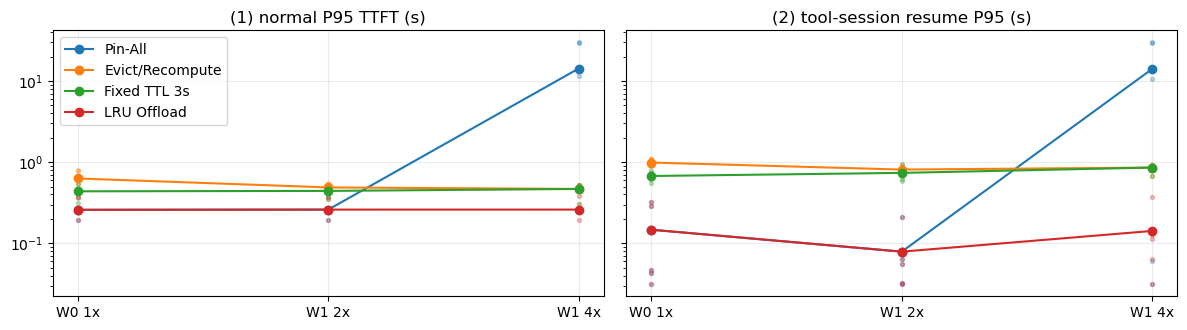

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (key, title) in zip(axes, [('normal_p95_ttft_ms', '(1) normal P95 TTFT (s)'),
                                   ('stress_resume_p95_ms', '(2) tool-session resume P95 (s)')]):
    for p in POLICIES:
        part = raw[raw.policy == p]
        ax.scatter(part.load.map(LOADS.index), part[key] / 1000, s=8, alpha=.3)
        mean = part.groupby('load')[key].mean().loc[LOADS] / 1000
        ax.plot(range(len(LOADS)), mean, marker='o', label=LABEL[p])
    ax.set(yscale='log', title=title, xticks=range(len(LOADS)), xticklabels=[f'{wl} {lv}x' for _, wl, lv in WEEK7_CONDITIONS])
    ax.grid(alpha=.25)
axes[0].legend()
plt.tight_layout()

## 10. 결론과 해석 범위

| 단계 | 얻은 것 | 대가 · 남은 문제 |
|---|---|---|
| 기준선 Pin-All | 대기가 짧으면 가장 빠름 (① 0.26s) | 4배에서 ① · ② 14초, 거절 · 작업 중단 |
| 단계 1 Evict/Recompute | 모든 조건 거절 0 | 매 복귀 재계산 → ② 0.8~1.0s, W0 ① 2.4배 |
| 단계 2 Fixed TTL 3s | 짧은 대기 보존 → ② 0.68s (W0) | 대기가 길어지면 단계 1과 같아짐 (고정값 한계) |
| 단계 3 LRU Offload | ①②③ 모두 기준선 1배 수준 | PCIe · CPU 메모리 자리표시자 → 실측 필요 |

- 결론: 대기가 짧으면 유지, 길면 비우는 쪽이 낫고, 비우는 방법(삭제 · 시간제 삭제 · 이동)에 따라 치르는 대가가 다릅니다.
- 다음 단계도 같은 지표 3개로 붙입니다: 동적 TTL(단계 2의 한계), 속도 실측 후 재실행, W2.
- 시뮬레이터 가정: prefill 단일 FIFO(실제 vLLM은 배치), 세션 간 decode 경합 없음, 속도 자리표시자. 절대값이 아니라 같은 가정 아래의 정책 간 변화로만 해석합니다.